# Libraries

In [1]:
# Standard
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Other
from IPython.display import display, Markdown

# Dataset

In [27]:
df_raw = pd.read_csv("raw_data/student-por.csv", sep=";")

# Data Cleaning

In [5]:
def data_structure(df):
    display(Markdown("## Dataset head"))
    display(df.head())
    display(Markdown("## Shape"))
    print(df.shape)
    display(Markdown("## Info"))
    print(df.info())
    display(Markdown("## Describe"))
    display(df.describe())
    display(Markdown("## Unique values"))
    print(df.nunique())
    display(Markdown("## Null"))
    print(df.isnull().sum())
    display(df[df.isna().any(axis=1)])
    display(Markdown("## Duplicates"))
    print(df.duplicated().sum())
    display(df[df.duplicated()])

In [28]:
data_structure(df_raw)

## Dataset head

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## Shape

(649, 33)


## Info

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

... (6 outputs left out)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3


## Duplicates

0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3


In [9]:
def plot_boxplots_grid(df, color="skyblue", ncols=2):

    numeric_cols = df.select_dtypes(include="number").columns

    if len(numeric_cols) == 0:
        print("No numeric variables")
        return

    n = len(numeric_cols)
    nrows = (n + ncols - 1) // ncols

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(6 * ncols, 4 * nrows)
    )

    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for i, col in enumerate(numeric_cols):

        sns.boxplot(
            x=df[col],
            color=color,
            ax=axes[i]
        )

        axes[i].set_title(f"Boxplot - {col}")
        axes[i].set_xlabel(col)

    # Removes unused axes
    for j in range(n, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


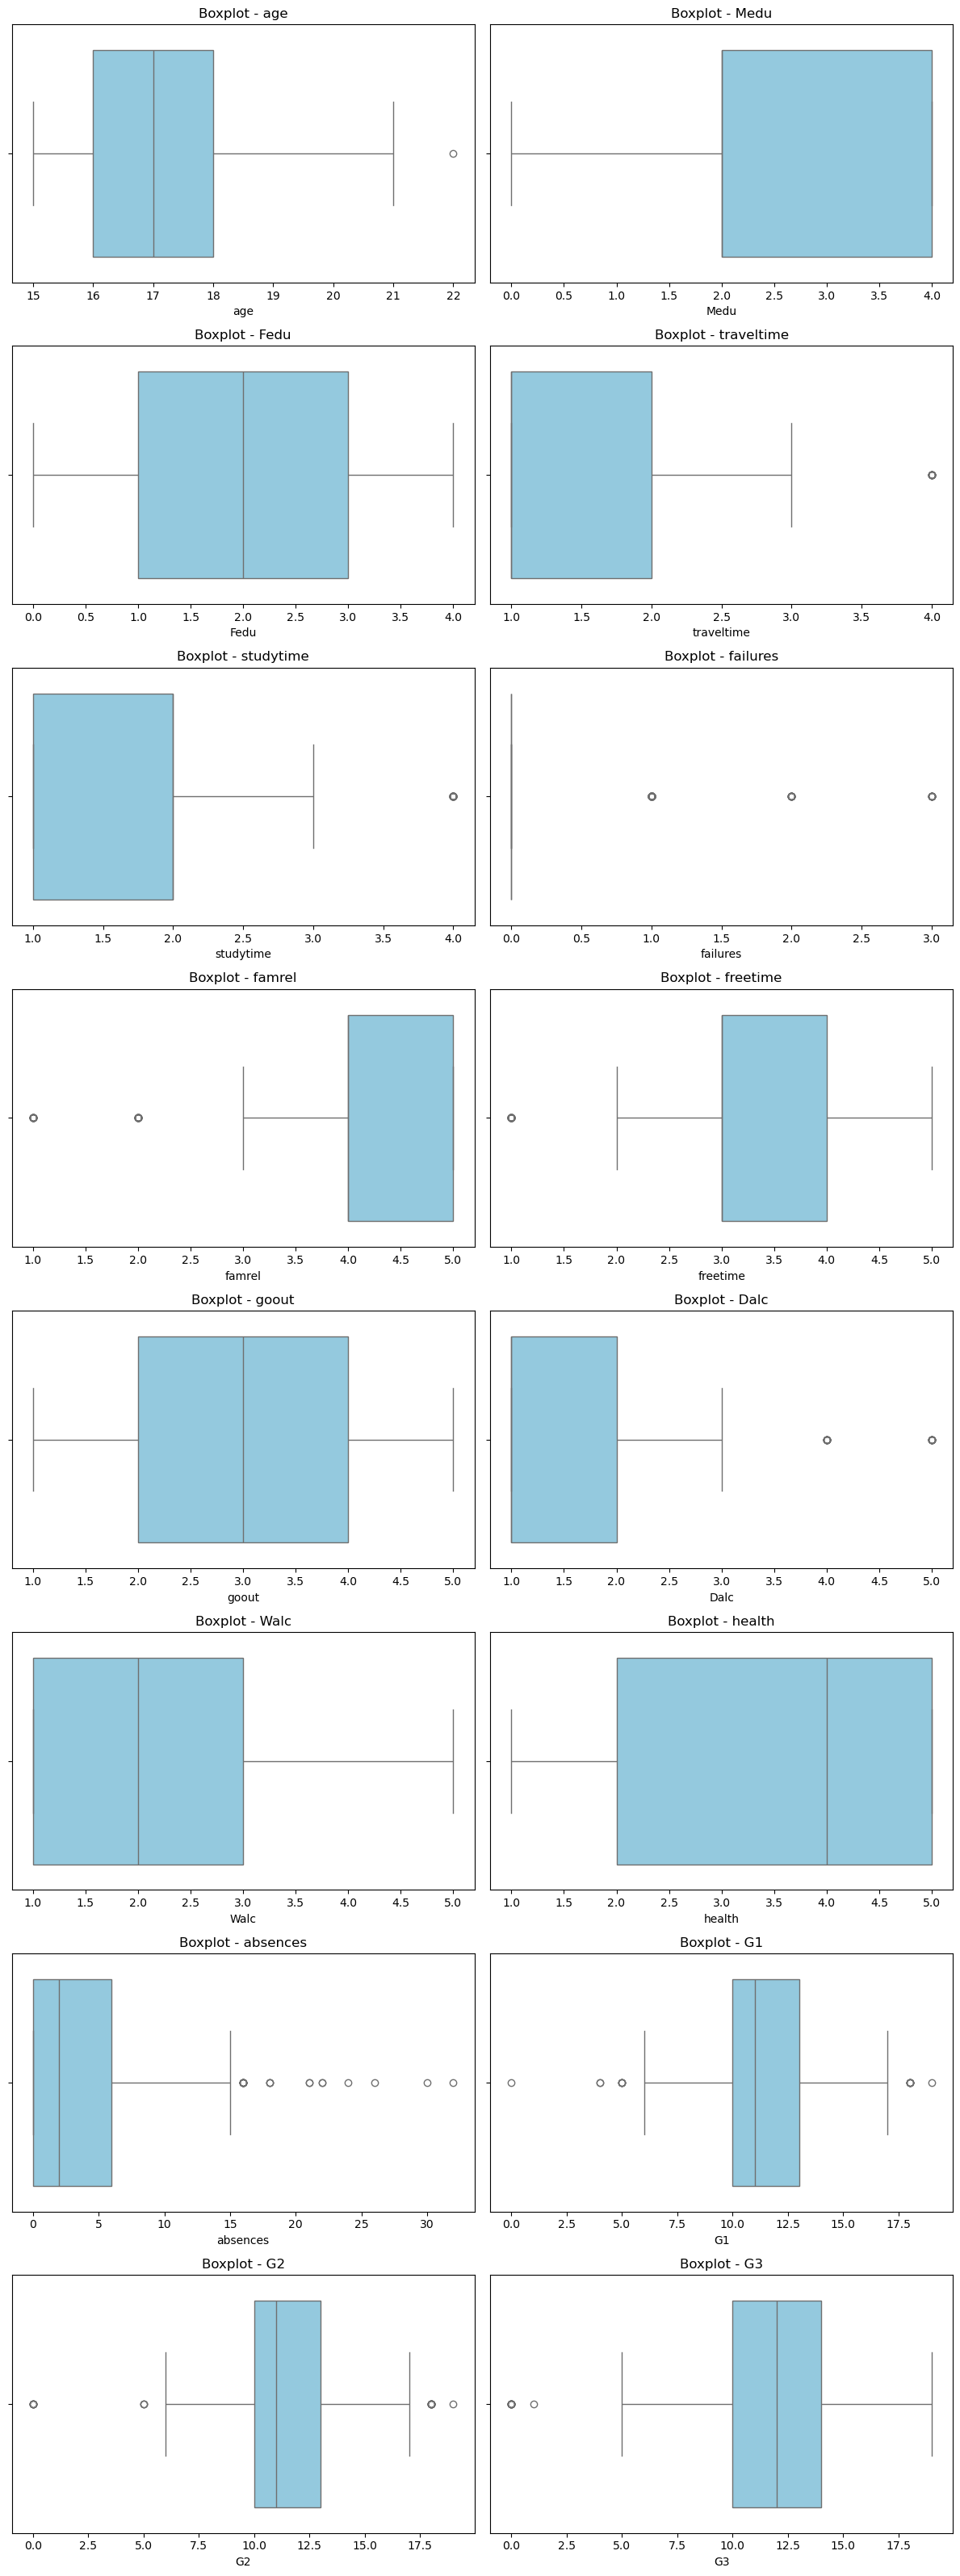

In [23]:
plot_boxplots_grid(df_raw)

# Data preprocessing

For a proper use in regression, some variables should be converted to numeric:
* Binary Encoding = binary variables should be converted to 0, 1 (convention, switching numbers does not compromise the results)
* One-Hot Encoding = for ordinal category variables with no natural order 

In [69]:
def binary_encoding(df):

    '''
    Does not modify original DataFrame
    Selects only categorical string columns
    Detects unique values (excluding NaN)
    If there are only 2, assigns 0 to the first and 1 to the second
    Keeps track of binary transformed columns in the list "binary columns"
    Keeps track of the correspondence between strings and 0, 1 in the list "mappings"
    '''
    df = df.copy()

    binary_columns = []
    mappings = []

    for col in df.select_dtypes(include=['object', 'category']).columns:
        unique_values = df[col].dropna().unique()

        if len(unique_values) == 2:
            mapping = {
                unique_values[0]: 0,
                unique_values[1]: 1
            }

            df[col] = df[col].map(mapping).astype("Int64")
            binary_columns.append(col)

            for original_value, encoded_value in mapping.items():
                mappings.append({
                    'variable': col,
                    'original_value': original_value,
                    'encoded_value': encoded_value
                })

    mappings_df = pd.DataFrame(mappings)

    return df, binary_columns, mappings_df

In [70]:
df, binary_columns, mappings_df = binary_encoding(df_raw)
mappings_df.to_csv("documentation/binary_encoding.csv", index=False)

print("Binary encoding:")
print(binary_columns)
display(mappings_df)

Binary encoding:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


C:\Users\Computer\AppData\Local\Temp\ipykernel_9008\2856327727.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object', 'category']).columns:


,variable,original_value,encoded_value
0,school,GP,0
1,school,MS,1
2,sex,F,0
3,sex,M,1
4,address,U,0
5,address,R,1
6,famsize,GT3,0
7,famsize,LE3,1
8,Pstatus,A,0
9,Pstatus,T,1


One-Hot Encoding (OHE) = transforms categorical non-binary variables into multiple binary columns (0, 1).\
The example with Mjob (mother's job) is:
* there are 5 categories = ['at_home', 'health', 'other', 'services', 'teacher']
* with OHE, 4 columns will be created = ['health', 'other', 'services', 'teacher'], that is all except from the first category
    * in each row, all columns will be 0 except the one with the original category
    * rows with all 0 will correspond to the category with no columns
    * this way, the sum of all columns is not always 5, that would cause a perfect correlation in the regression (dummy variable trap)

In [74]:
def one_hot_encode(df, columns):

    '''
    Does not modify original DataFrame
    Works only on selected columns
    Creates n-1 columns per categorical column, where n = original categories of original column 
    Transforms categories into numbers
    '''

    df = df.copy()

    df = pd.get_dummies(
        df,
        columns=columns,
        drop_first=True,
        dtype=int
    )

    return df

In [75]:
categorical_columns = ['Mjob', 'Fjob', 'reason', 'guardian']

df = one_hot_encode(df, categorical_columns)

# EDA

In [76]:
data_structure(df)

## Dataset head

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,...,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other
0,0,0,18,0,0,0,4,4,2,2,...,0,0,0,0,1,0,0,0,1,0
1,0,0,17,0,0,1,1,1,1,2,...,0,0,1,0,0,0,0,0,0,0
2,0,0,15,0,1,1,1,1,1,2,...,0,0,1,0,0,0,1,0,1,0
3,0,0,15,0,0,1,4,2,1,3,...,0,0,0,1,0,1,0,0,1,0
4,0,0,16,0,0,1,3,3,1,2,...,0,0,1,0,0,1,0,0,0,0


## Shape

(649, 42)


## Info

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 42 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   school             649 non-null    Int64
 1   sex                649 non-null    Int64
 2   age                649 non-null    int64
 3   address            649 non-null    Int64
 4   famsize            649 non-null    Int64
 5   Pstatus            649 non-null    Int64
 6   Medu               649 non-null    int64
 7   Fedu               649 non-null    int64
 8   traveltime         649 non-null    int64
 9   studytime          649 non-null    int64
 10  failures           649 non-null    int64
 11  schoolsup          649 non-null    Int64
 12  famsup             649 non-null    Int64
 13  paid               649 non-null    Int64
 14  activities         649 non-null    Int64
 15  nursery            649 non-null    Int64
 16  higher             649 non-null    Int64
 17  internet           649 non-

... (6 outputs left out)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,...,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other


## Duplicates

0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,...,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other


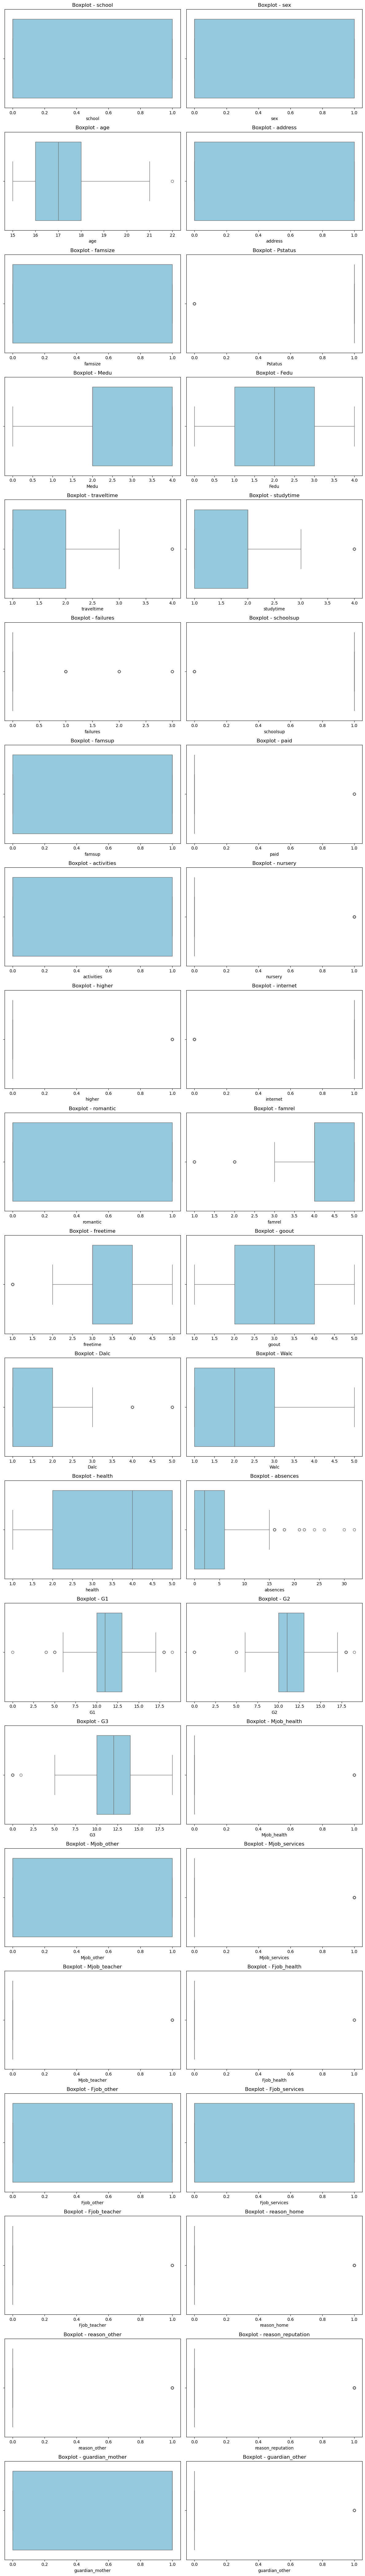

In [77]:
plot_boxplots_grid(df)

For non-binary non-ordinal categories (treated with OHE), a dedicated plot is more suitable

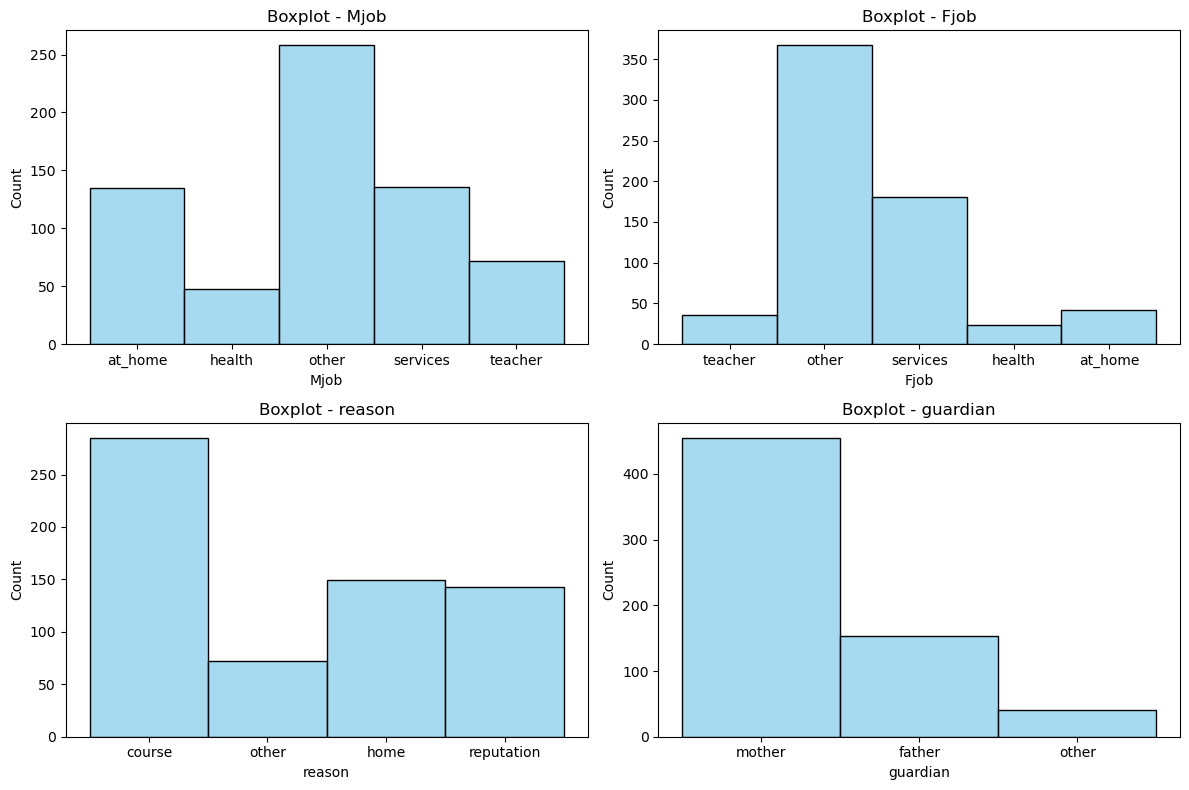

In [85]:
ncols = 2
color="skyblue"
numeric_cols = categorical_columns

n = len(numeric_cols)
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(6 * ncols, 4 * nrows)
)

axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i, col in enumerate(numeric_cols):

    sns.histplot(
        x=df_raw[col],
        color=color,
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot - {col}")
    axes[i].set_xlabel(col)

# Removes unused axes
for j in range(n, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [78]:
df.to_csv("processed_data/encoded.csv", index=False)